# Workshop 1: Python & NumPy

**Real-life problem:** Will I run out of money before the end of term, and how much do I need on hand to be safe?

**My twist:** Calibrate a simulation on 12 months of my own bank statements (rounded figures, no merchants or names): weekly spending that is lumpy rather than bell-shaped, planned big payments, and a short internship. NumPy (broadcasting, `cumsum`, `np.random`) simulates 10,000 versions of each of my three terms at once.

**Done when:** A plot of balance over the term with a 5th–95th percentile band, and one sentence: the probability of going below zero and what weekly spend cap keeps it under 5%.

*Baseline = the lecturer's workshop code (unmodified copy in `_baseline/`). Everything below the line starts as that baseline; edit it.*

---


## Part A: NumPy and Matplotlib essentials (condensed from the PDF)

The PDF is a tour of Python basics (types, lists, dictionaries, classes), then NumPy, then Matplotlib. I skipped the Python basics and ported the examples Part B actually uses: arrays and shapes, slicing, indexing, array math, **broadcasting**, and a first plot.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# an array has a shape and one data type
a = np.array([[1, 2, 3, 4], [5, 6, 7, 8], [9, 10, 11, 12]])
print(a.shape, a.dtype)             # (3, 4) int64

# slicing: mixing an integer with a slice gives a lower-rank result
row_r1 = a[1, :]                    # shape (4,)
row_r2 = a[1:2, :]                  # shape (1, 4)
print(row_r1.shape, row_r2.shape)

# a slice is a VIEW of the same data: changing it changes the original
b = a[:2, 1:3]
b[0, 0] = 77
print(a[0, 1])                      # 77

(3, 4) int64
(4,) (1, 4)
77


In [2]:
# integer-array indexing and boolean indexing
m = np.array([[1, 2], [3, 4], [5, 6]])
print(m[[0, 1, 2], [0, 1, 0]])      # picks m[0,0], m[1,1], m[2,0]  ->  [1 4 5]
print(m[m > 2])                     # every element bigger than 2   ->  [3 4 5 6]

[1 4 5]
[3 4 5 6]


In [3]:
# array math is element-by-element; dot() is matrix multiplication; sum() can go along an axis
x = np.array([[1, 2], [3, 4]], dtype=np.float64)
y = np.array([[5, 6], [7, 8]], dtype=np.float64)
print(x + y)
print(x * y)                        # element-wise, NOT matrix multiplication
print(x.dot(y))                     # matrix multiplication
print(np.sum(x), np.sum(x, axis=0), np.sum(x, axis=1))   # all, per column, per row

[[ 6.  8.]
 [10. 12.]]
[[ 5. 12.]
 [21. 32.]]
[[19. 22.]
 [43. 50.]]
10.0 [4. 6.] [3. 7.]


In [4]:
# broadcasting: add a vector to every row without writing a loop
x = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9], [10, 11, 12]])   # shape (4, 3)
v = np.array([1, 0, 1])                                           # shape (3,)

y_loop = np.empty_like(x)
for i in range(4):                  # the slow way
    y_loop[i, :] = x[i, :] + v

y = x + v                           # the NumPy way: v is stretched across the 4 rows
print(np.array_equal(y, y_loop))
print(np.reshape(np.array([1, 2, 3]), (3, 1)) * np.array([4, 5]))   # outer product via broadcasting

True
[[ 4  5]
 [ 8 10]
 [12 15]]


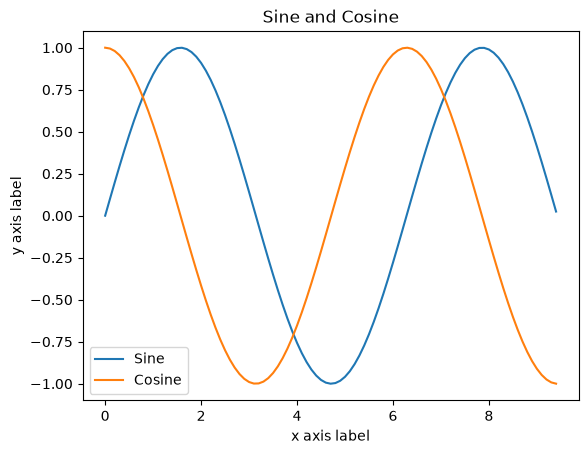

In [5]:
x = np.arange(0, 3 * np.pi, 0.1)
plt.plot(x, np.sin(x))
plt.plot(x, np.cos(x))
plt.xlabel('x axis label'); plt.ylabel('y axis label'); plt.title('Sine and Cosine')
plt.legend(['Sine', 'Cosine'])
plt.show()

---
## Part B: real life: how much outside money does each term need?

**Question:** I get through each term with a bank balance close to zero. **Will I run out before the end of term, and how much money do I need on hand (from anywhere other than funding and pay) to be safe?**

**Where the numbers come from:** 12 months of my own bank statements across two accounts (September 2025 to August 2026), covering three terms. To keep this safe to publish, **every figure below is rounded** (to the nearest £5, £50 or £100) and no merchants, names or account details appear.

**What the statements showed**
- **I live near zero.** My balance at the start of each term was between £0 and about £300.
- **Funding pays rent.** Funding arrives in lumps and goes straight out as rent, so it never touches day-to-day money. Over the year, rent was about £5,850 and funding about £4,600.
- **Spending is lumpy.** In a typical term a few weeks are very expensive and others cost almost nothing, so the *spread* of weekly spending is about as large as its average. A bell curve (what I assumed in the first version of this notebook) fits that badly.
- **Big payments are planned**, not surprises.
- **Pay is short:** a three-week internship (20 July to 7 August) at £12.71 an hour, 20 hours a week, about £254 a week.

**Method:** for each term, simulate 10,000 possible versions: random weekly spending plus the known payments, tracked as a running balance with `cumsum`. The number that matters is the **peak shortfall**: the most the balance sinks below zero, which is the cash I'd need on hand to never run out.

**Rounded inputs per term**

| | Term 1 (Sep to Dec 25) | Term 2 (Jan to May 26) | Term 3 (Jun to early Sep 26) |
|---|---|---|---|
| Weeks | 14 | 21 | 13 |
| Everyday card spending, average week | £170 | £185 | £115 |
| Typical week-to-week spread | £180 | £125 | £130 |
| Planned big payments (week of term) | £150 (1), £1,600 (5), £550 (8) | £450 (17) | £200 (2) |
| Pay | none | none | £254 a week in weeks 8 to 10 |

Everyday spending combines the card spending from both accounts (adding the two weekly amounts and ignoring transfers between them). Rent and funding are handled separately in section 4.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N = 10_000            # simulated versions of each term
START = 0             # balance at the start of a term was near zero (about £0 to £300 in practice)

TERMS = {
    'Term 1': dict(weeks=14, mean=170, sd=180, planned={1: 150, 5: 1600, 8: 550}, pay={}),
    'Term 2': dict(weeks=21, mean=185, sd=125, planned={17: 450},                 pay={}),
    'Term 3': dict(weeks=13, mean=115, sd=130, planned={2: 200},                  pay={8: 254.2, 9: 254.2, 10: 254.2}),
}

def simulate(term, n=N, seed=42, cap=None, with_pay=True):
    """Running balance after each week, shape (n versions, weeks), with no outside money added."""
    p = TERMS[term]; W = p['weeks']
    shape, scale = (p['mean'] / p['sd']) ** 2, p['sd'] ** 2 / p['mean']      # skewed (gamma) weekly spending: never negative, a long tail
    spend = np.random.default_rng(seed).gamma(shape, scale, (n, W))
    if cap is not None:
        spend = np.minimum(spend, cap)                                        # a weekly spending cap
    planned, pay = np.zeros(W), np.zeros(W)
    for wk, amount in p['planned'].items(): planned[wk - 1] = amount
    if with_pay:
        for wk, amount in p['pay'].items(): pay[wk - 1] = amount
    return START + np.cumsum(pay - planned - spend, axis=1)                   # (W,) vectors broadcast across all n versions

def peak_shortfall(bal):
    return np.maximum(0, -bal.min(axis=1))                                    # how far below zero the balance sinks at worst

bal = {t: simulate(t) for t in TERMS}
need = {t: peak_shortfall(bal[t]) for t in TERMS}

summary = pd.DataFrame({
    t: {'weeks': TERMS[t]['weeks'],
        'expected everyday spending (£)': TERMS[t]['mean'] * TERMS[t]['weeks'],
        'planned big payments (£)': sum(TERMS[t]['planned'].values()),
        'pay (£)': sum(TERMS[t]['pay'].values()),
        'chance of dipping below zero (%)': (need[t] > 0).mean() * 100,
        'cash needed, typical (median) (£)': np.median(need[t]),
        'cash needed, bad case (95th percentile) (£)': np.percentile(need[t], 95)}
    for t in TERMS}).round(0).astype(int)
summary

,Term 1,Term 2,Term 3
weeks,14,21,13
expected everyday spending (£),2380,3885,1495
planned big payments (£),2300,450,200
pay (£),0,0,763
chance of dipping below zero (%),100,100,100
"cash needed, typical (median) (£)",4639,4302,1057
"cash needed, bad case (95th percentile) (£)",5888,5326,1847


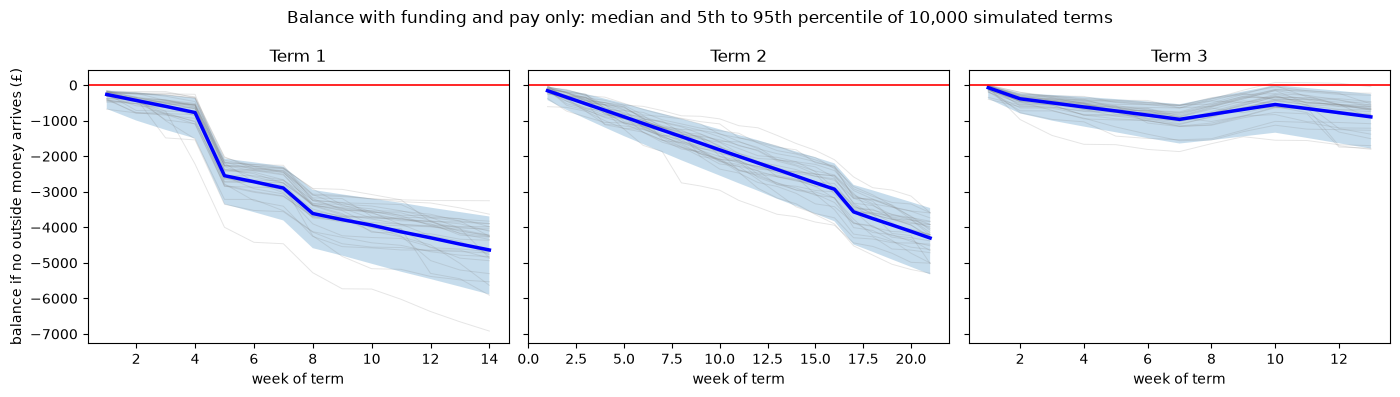

In [7]:
fig, axes = plt.subplots(1, len(TERMS), figsize=(4.7 * len(TERMS), 4), sharey=True, squeeze=False)
for ax, t in zip(axes[0], TERMS):
    W = TERMS[t]['weeks']; wk = np.arange(1, W + 1)
    p5, p50, p95 = np.percentile(bal[t], [5, 50, 95], axis=0)
    ax.plot(wk, bal[t][:30].T, color='grey', alpha=0.2, lw=0.7)
    ax.fill_between(wk, p5, p95, alpha=0.25)
    ax.plot(wk, p50, 'b-', lw=2.5)
    ax.axhline(0, color='r', lw=1.2)
    ax.set_title(t); ax.set_xlabel('week of term')
axes[0][0].set_ylabel('balance if no outside money arrives (£)')
fig.suptitle('Balance with funding and pay only: median and 5th to 95th percentile of 10,000 simulated terms')
plt.tight_layout(); plt.show()

- **With funding and pay only, every simulated term goes below zero (100%).** That is not a forecast of disaster, it is the point: my day-to-day money has to come from somewhere else, so the real question is how much.
- **Typical cash needed:** about **£4,600 in Term 1**, **£4,300 in Term 2** and **£1,050 in Term 3**. In a bad case (1 term in 20): about **£5,900, £5,300 and £1,850**.
- **Term 1 is driven by planned payments:** £2,300 of its £4,640 typical need is three planned payments, and one of them (£1,600 in week 5) is the biggest single item.
- **Term 2 is driven by everyday spending:** it is the longest term (21 weeks) and the one with the highest weekly spend.
- **Term 3 is the cheapest**, helped by the internship pay in weeks 8 to 10.

### 2. Why not just plan for the average week?
A budget built on the *average* week looks fine on paper. But spending is lumpy, so some terms are much worse than average. Compare the "average-week" budget with the cash needed in a bad case:

In [8]:
avg_budget = pd.Series({t: max(0, TERMS[t]['mean'] * TERMS[t]['weeks'] + sum(TERMS[t]['planned'].values()) - sum(TERMS[t]['pay'].values()))
                        for t in TERMS})
compare = pd.DataFrame({'average-week budget (£)': avg_budget,
                        'typical cash needed, simulated (£)': {t: np.median(need[t]) for t in TERMS},
                        'bad-case cash needed, 95th percentile (£)': {t: np.percentile(need[t], 95) for t in TERMS}}).round(0).astype(int)
compare['bad case vs average-week budget'] = (compare['bad-case cash needed, 95th percentile (£)'] / compare['average-week budget (£)']).round(2)
compare

,average-week budget (£),"typical cash needed, simulated (£)","bad-case cash needed, 95th percentile (£)",bad case vs average-week budget
Term 1,4680,4639,5888,1.26
Term 2,4335,4302,5326,1.23
Term 3,932,1057,1847,1.98


- **A plan built on the average week is about right for a typical outcome** (Term 1: £4,680 planned vs £4,640 simulated; Term 2: £4,335 vs £4,300).
- **But the bad case needs about £1,000 more than the average-week plan in every term:** +£1,208 in Term 1, +£991 in Term 2, +£915 in Term 3. That is the price of lumpy spending, and it is roughly the same size in each term.
- **Term 3 looks worse as a ratio** (nearly 2x) only because its average-week budget is small; in pounds the extra is similar.

So the safe amount to hold is the average-week budget **plus about £1,000**.

### 3. Does a weekly spending cap help?
Cap the *everyday* spending in any one week at £X (planned big payments are unaffected). `np.minimum` with broadcasting stretches every cap across all 10,000 versions and every week at once, reusing the same random terms so the comparison is fair.

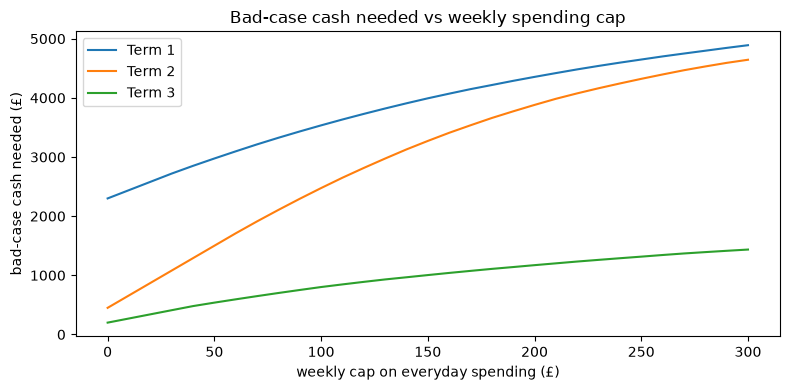

,no cap,cap £150,cap £100,cap £50
Term 1,5888,3992,3535,2975
Term 2,5326,3272,2475,1500
Term 3,1847,1004,802,538


In [9]:
caps = np.arange(0, 301, 10)                                              # shape (31,)
fig, ax = plt.subplots(figsize=(8, 4))
rows = {}
for t in TERMS:
    p = TERMS[t]; W = p['weeks']
    shape, scale = (p['mean'] / p['sd']) ** 2, p['sd'] ** 2 / p['mean']
    spend = np.random.default_rng(42).gamma(shape, scale, (N, W))
    other = np.zeros(W)
    for wk, a in p['pay'].items(): other[wk - 1] += a
    for wk, a in p['planned'].items(): other[wk - 1] -= a
    capped = np.minimum(spend[None, :, :], caps[:, None, None])             # (1,N,W) vs (31,1,1) -> (31,N,W)
    cum = np.cumsum(other[None, None, :] - capped, axis=2)                   # (31,N,W)
    p95 = np.percentile(np.maximum(0, -cum.min(axis=2)), 95, axis=1)         # bad-case cash needed for each cap
    ax.plot(caps, p95, label=t)
    rows[t] = {'no cap': np.percentile(peak_shortfall(simulate(t)), 95), 'cap £150': p95[caps == 150][0], 'cap £100': p95[caps == 100][0], 'cap £50': p95[caps == 50][0]}
ax.set_xlabel('weekly cap on everyday spending (£)'); ax.set_ylabel('bad-case cash needed (£)')
ax.set_title('Bad-case cash needed vs weekly spending cap'); ax.legend(); plt.tight_layout(); plt.show()
pd.DataFrame(rows).T.round(0).astype(int)

- **A weekly cap on everyday spending is the biggest lever in the model.** The bad-case cash needed falls from £5,300 to £2,500 (-54%) in Term 2 with a £100-a-week cap, and to £1,500 (-72%) with a £50 cap.
- **Term 1 gains less** (£5,900 to £3,500 at a £100 cap, -40%) because planned payments are £2,300 of its need and no cap touches them. **Term 3** goes from £1,850 to £800 (-57%).
- **Read the cap as showing where the money is, not as a realistic rule.** A £50 cap means never spending more than £50 in any single week, which the expensive weeks (travel, nights out) would break. The takeaway: a few expensive weeks drive most of the need.

### 4. The internship and the rent

In [10]:
no_pay = peak_shortfall(simulate('Term 3', with_pay=False))
print(f'Term 3, 95th percentile cash needed: £{np.percentile(no_pay, 95):,.0f} without the internship, '
      f'£{np.percentile(need["Term 3"], 95):,.0f} with it')
print(f'internship pay £{sum(TERMS["Term 3"]["pay"].values()):,.0f} = {sum(TERMS["Term 3"]["pay"].values()) / (TERMS["Term 3"]["mean"] * TERMS["Term 3"]["weeks"] + sum(TERMS["Term 3"]["planned"].values())) * 100:.0f}% of Term 3 expected spending')

RENT_PAID, FUNDING = 5850, 4600          # rounded totals over the year
print(f'\nrent over the year about £{RENT_PAID:,}; funding about £{FUNDING:,}: funding covers {FUNDING / RENT_PAID * 100:.0f}% of rent, a gap of about £{RENT_PAID - FUNDING:,}')

Term 3, 95th percentile cash needed: £2,547 without the internship, £1,847 with it
internship pay £763 = 45% of Term 3 expected spending

rent over the year about £5,850; funding about £4,600: funding covers 79% of rent, a gap of about £1,250


- **The internship** (£763) covers about 45% of Term 3's expected spending and cuts the bad-case cash needed from about £2,550 to £1,850, roughly £700 less.
- **Rent:** funding covered about 79% of the year's rent (about £4,600 of £5,850). The remaining gap of about £1,250 is another outside-money need on top of the term figures above.

### Finding
**I run each term near zero, so without outside money I would run out in every term; the useful question is how much I need on hand.** Typically about £4,600 in Term 1 (half of it three planned payments), £4,300 in Term 2 (the longest, highest-spending term) and £1,050 in Term 3 (the cheapest, helped by the internship). In a bad case, about £5,900, £5,300 and £1,850. Because weekly spending is lumpy, the safe amount is roughly **£1,000 above an average-week budget** in every term. Capping everyday spending at £100 a week would cut the bad-case need by 40% to 57%. Over the year that is roughly £10,000 of living costs plus a £1,250 rent gap that funding and pay don't cover.

**Caveats:** all figures are rounded and come from one person's year. The two accounts' weekly spending is added as if independent, so if I shift spending between accounts the true combined variation is smaller and the buffers a little overstated. Each term has only 13 to 21 weeks of data. Planned payments may not repeat. "Outside money" is anything other than funding and pay, and the statements don't show where it comes from.

**Next:** use the term you are about to start: put its weeks, planned payments and pay into `TERMS` and read the cash-needed figures straight off the table.